# 🌾 Week 1: Geospatial & Weather Data Integration
**Axlero Data Science & Machine Learning Internship — Project 3: Agriculture & Rural Businesses**  
*Crop Yield & Soil Analysis Forecasting System*

---

## 🎯 Engineering Focus & Objectives
1. **Multi-Source Data Ingestion**: Load heterogeneous daily weather time-series, static regional soil chemistry profiles, and historical agricultural yield records.
2. **Phenological Weather Aggregations**: Transform high-frequency daily meteorology into biologically relevant growing-season metrics (Cumulative Rainfall, Growing Degree Days [GDD], and Extreme Heat Stress Days).
3. **Geospatial & Temporal Data Fusion**: Merge temporal weather indicators with static soil composition using geographic identifiers (`district_id`) and temporal keys (`year`).
4. **Data Integrity & Spatial Leakage Pre-checks**: Validate that all districts are accounted for with zero geographic join dropouts or anomalies.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual aesthetic
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.size'] = 11

print('Libraries successfully imported.')


Libraries successfully imported.


## 📂 1. Raw Data Ingestion & Schema Inspection
We ingest three distinct data modalities from `data/raw/`:
- `weather_daily.csv`: Daily observations of maximum/minimum temperature, rainfall, and humidity.
- `soil_chemistry.csv`: Static geographic chemical composition (pH, Nitrogen, Phosphorus, Potassium, Organic Carbon).
- `historical_yields.csv`: Annual crop yield records (MT/Ha) across agricultural districts and crop varieties.


In [2]:
weather_raw = pd.read_csv('../data/raw/weather_daily.csv')
soil_raw = pd.read_csv('../data/raw/soil_chemistry.csv')
yield_raw = pd.read_csv('../data/raw/historical_yields.csv')

print(f"Daily Weather Records : {weather_raw.shape[0]:,} rows across {weather_raw['district_id'].nunique()} districts")
print(f"Soil Chemistry Profiles: {soil_raw.shape[0]} districts profiled")
print(f"Historical Yields     : {yield_raw.shape[0]} annual observations")


Daily Weather Records : 21,910 rows across 10 districts
Soil Chemistry Profiles: 10 districts profiled
Historical Yields     : 240 annual observations


In [3]:
soil_raw.head(10)


,district_id,district_name,soil_type,ph,nitrogen,phosphorus,potassium,organic_carbon_pct,cation_exchange_capacity
0,DIST_01,Midwest Plain A,Clay Loam,6.4,115,38,140,2.1,24.5
1,DIST_02,River Valley B,Alluvial,6.8,135,45,160,2.8,28.0
2,DIST_03,Highland Hills C,Sandy Loam,5.6,85,25,95,1.4,18.2
3,DIST_04,Central Basin D,Black Soil,7.2,125,40,150,2.4,30.1
4,DIST_05,Southern Prairie E,Red Loam,6.1,95,30,110,1.8,21.0
5,DIST_06,Northern Plateau F,Clay Loam,5.9,105,34,125,2.0,23.4
6,DIST_07,Eastern Delta G,Alluvial,6.9,140,48,175,3.1,29.5
7,DIST_08,Western Terraces H,Sandy Loam,5.4,75,22,85,1.2,16.5
8,DIST_09,Lakeside Flat I,Silt Loam,6.5,120,42,145,2.5,26.0
9,DIST_10,Sunny Ridge J,Red Loam,6.3,110,36,130,1.9,22.8


## ⛅ 2. Phenological Weather Aggregation
Raw daily meteorological observations cannot be directly matched with seasonal crop yields. We compute:
* **Cumulative Rainfall (mm)**: Total water availability across the vegetative and grain-filling stages.
* **Growing Degree Days (GDD)**: Thermal heat accumulation above base threshold T_base = 10°C:
* **Heat Stress Days**: Frequency of days where T_max >= 35°C, triggering pollen sterility and yield reduction.


In [4]:
# Calculate daily agronomic indicators
weather_df = weather_raw.copy()
weather_df['gdd'] = np.maximum(0.0, (weather_df['temp_max'] + weather_df['temp_min']) / 2.0 - 10.0)
weather_df['heat_stress_day'] = (weather_df['temp_max'] >= 35.0).astype(int)
weather_df['rainy_day'] = (weather_df['precipitation'] > 1.0).astype(int)

# Aggregate per district and year
agg_rules = {
    'precipitation': ['sum', 'mean', 'std'],
    'temp_max': ['mean', 'max'],
    'temp_min': ['mean', 'min'],
    'temp_mean': ['mean'],
    'humidity': ['mean', 'min', 'max'],
    'solar_radiation': ['mean', 'sum'],
    'gdd': ['sum'],
    'heat_stress_day': ['sum'],
    'rainy_day': ['sum']
}

weather_agg = weather_df.groupby(['district_id', 'year']).agg(agg_rules)
weather_agg.columns = [f"{col}_{func}" if func != 'sum' else f"cumulative_{col}" if col in ['precipitation', 'gdd'] else f"total_{col}"
                       for col, func in weather_agg.columns.values]
weather_agg = weather_agg.reset_index()

print("Aggregated Weather Matrix Shape:", weather_agg.shape)
weather_agg.head()


Aggregated Weather Matrix Shape: (60, 18)


,district_id,year,cumulative_precipitation,precipitation_mean,precipitation_std,temp_max_mean,temp_max_max,temp_min_mean,temp_min_min,temp_mean_mean,humidity_mean,humidity_min,humidity_max,solar_radiation_mean,total_solar_radiation,cumulative_gdd,total_heat_stress_day,total_rainy_day
0,DIST_01,2018,1361.20,3.729315,10.095588,18.590740,34.80,8.541315,-6.39,13.566164,55.516411,25.00,92.48,17.201890,6278.69,2138.800,0,90
1,DIST_01,2019,1133.66,3.105918,8.192866,18.820356,35.12,8.659863,-6.80,13.740329,55.096849,25.32,86.15,17.338877,6328.69,2146.670,1,85
2,DIST_01,2020,1543.15,4.216257,10.446375,18.607486,34.66,8.851148,-7.33,13.729508,55.316011,25.00,96.13,17.198661,6294.71,2173.175,0,93
3,DIST_01,2021,1589.02,4.353479,11.476996,18.700932,34.35,8.685918,-7.78,13.693616,55.302658,28.10,88.86,17.141918,6256.80,2146.640,0,93
4,DIST_01,2022,1207.16,3.307288,8.425122,18.796877,35.71,8.634932,-7.00,13.715945,54.582986,25.00,91.88,17.257151,6298.86,2136.805,1,79


## 🔗 3. Geospatial & Temporal Master Data Fusion
We join the aggregated seasonal meteorology with static soil chemistry and annual crop harvest outputs using `district_id` and `year`.


In [5]:
import sys
sys.path.append('..')
from src.data_fusion import fuse_datasets

master_df = fuse_datasets(weather_agg, soil_raw, yield_raw, key='district_id')
print(f"Master Dataset Dimensions: {master_df.shape[0]} rows x {master_df.shape[1]} columns")
print(f"Missing value count across all features: {master_df.isnull().sum().sum()}")
master_df.head()


2026-10-17 18:18:41,622 [INFO] Fusing datasets using spatial identifier 'district_id' and temporal key 'year'...


2026-10-17 18:18:41,630 [INFO] Merged Yield + Soil shape: (240, 15)


2026-10-17 18:18:41,631 [INFO] Master Dataset Fusion Complete. Final Shape: (240, 31), Missing Values: 0


Master Dataset Dimensions: 240 rows x 31 columns
Missing value count across all features: 0


,district_id,year,crop_type,cultivar,planting_month,harvest_month,yield_mt_per_ha,district_name,soil_type,ph,...,temp_min_min,temp_mean_mean,humidity_mean,humidity_min,humidity_max,solar_radiation_mean,total_solar_radiation,cumulative_gdd,total_heat_stress_day,total_rainy_day
0,DIST_01,2018,Wheat,Wheat-Cultivar-X,11,4,3.62,Midwest Plain A,Clay Loam,6.4,...,-6.39,13.566164,55.516411,25.00,92.48,17.201890,6278.69,2138.80,0,90
1,DIST_01,2018,Maize,Maize-Cultivar-X,5,10,6.92,Midwest Plain A,Clay Loam,6.4,...,-6.39,13.566164,55.516411,25.00,92.48,17.201890,6278.69,2138.80,0,90
2,DIST_01,2018,Soybean,Soybean-Cultivar-X,5,10,2.98,Midwest Plain A,Clay Loam,6.4,...,-6.39,13.566164,55.516411,25.00,92.48,17.201890,6278.69,2138.80,0,90
3,DIST_01,2018,Rice,Rice-Cultivar-X,5,10,6.57,Midwest Plain A,Clay Loam,6.4,...,-6.39,13.566164,55.516411,25.00,92.48,17.201890,6278.69,2138.80,0,90
4,DIST_01,2019,Wheat,Wheat-Cultivar-Y,11,4,3.91,Midwest Plain A,Clay Loam,6.4,...,-6.80,13.740329,55.096849,25.32,86.15,17.338877,6328.69,2146.67,1,85


## 📊 4. Exploratory Data Analysis (EDA) & Spatial Distributions
We analyze spatial variance across districts to understand how regional soil quality and climate variations influence yield.


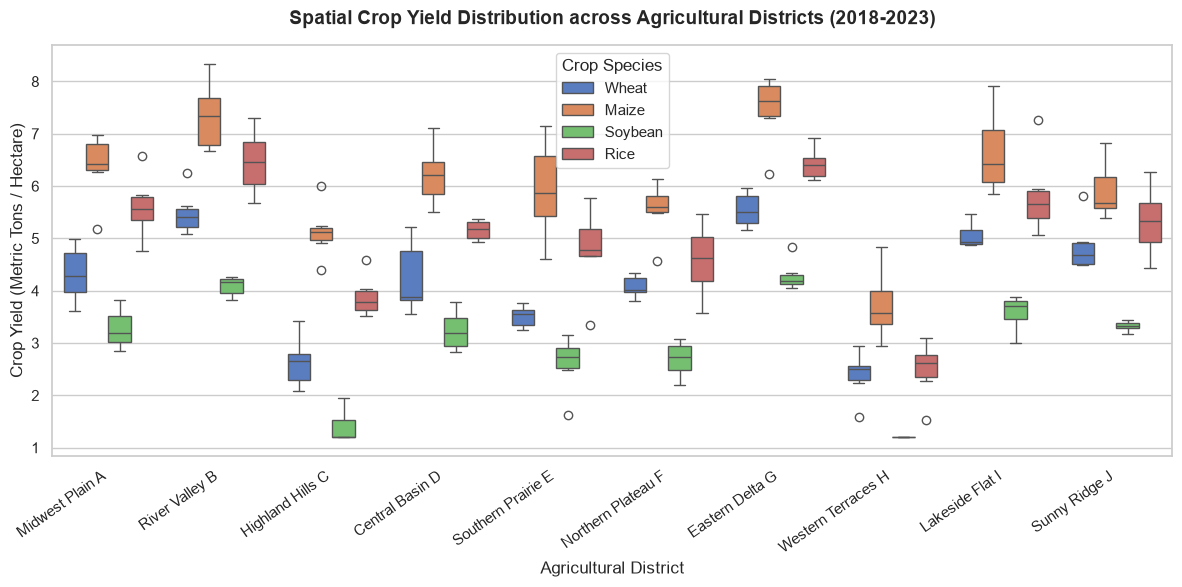

In [6]:
# 4.1 Spatial Yield Distribution by District and Crop
plt.figure(figsize=(12, 6))
sns.boxplot(data=master_df, x='district_name', y='yield_mt_per_ha', hue='crop_type')
plt.title('Spatial Crop Yield Distribution across Agricultural Districts (2018-2023)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Agricultural District', fontsize=12)
plt.ylabel('Crop Yield (Metric Tons / Hectare)', fontsize=12)
plt.xticks(rotation=35, ha='right')
plt.legend(title='Crop Species', frameon=True)
plt.tight_layout()
plt.show()


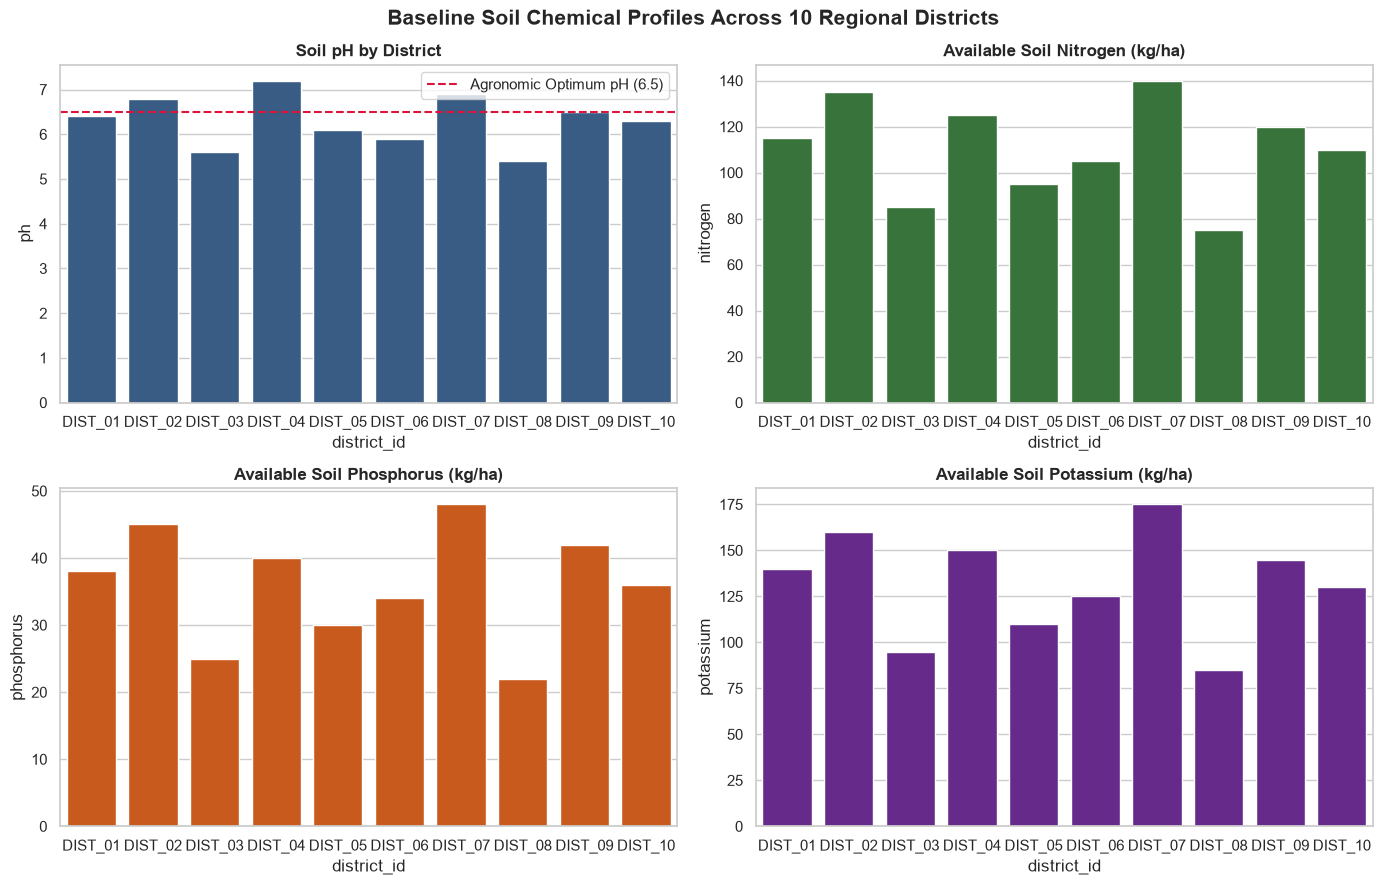

In [7]:
# 4.2 Soil Chemical Distribution across Profiling Districts
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.barplot(data=soil_raw, x='district_id', y='ph', ax=axes[0, 0], color='#2b5c8f')
axes[0, 0].axhline(6.5, color='crimson', linestyle='--', label='Agronomic Optimum pH (6.5)')
axes[0, 0].set_title('Soil pH by District', fontweight='bold')
axes[0, 0].legend()

sns.barplot(data=soil_raw, x='district_id', y='nitrogen', ax=axes[0, 1], color='#2e7d32')
axes[0, 1].set_title('Available Soil Nitrogen (kg/ha)', fontweight='bold')

sns.barplot(data=soil_raw, x='district_id', y='phosphorus', ax=axes[1, 0], color='#e65100')
axes[1, 0].set_title('Available Soil Phosphorus (kg/ha)', fontweight='bold')

sns.barplot(data=soil_raw, x='district_id', y='potassium', ax=axes[1, 1], color='#6a1b9a')
axes[1, 1].set_title('Available Soil Potassium (kg/ha)', fontweight='bold')

plt.suptitle('Baseline Soil Chemical Profiles Across 10 Regional Districts', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


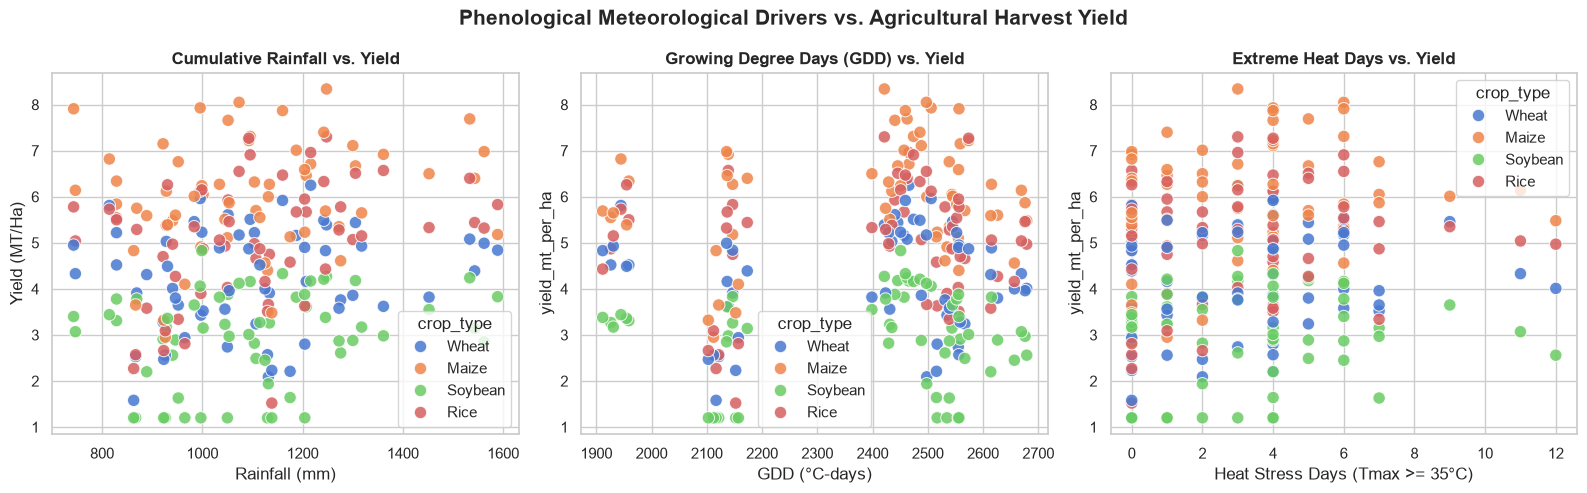

In [8]:
# 4.3 Weather Stress & Growing Degree Days vs. Yield
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.scatterplot(data=master_df, x='cumulative_precipitation', y='yield_mt_per_ha', hue='crop_type', ax=axes[0], s=80, alpha=0.85)
axes[0].set_title('Cumulative Rainfall vs. Yield', fontweight='bold')
axes[0].set_xlabel('Rainfall (mm)')
axes[0].set_ylabel('Yield (MT/Ha)')

sns.scatterplot(data=master_df, x='cumulative_gdd', y='yield_mt_per_ha', hue='crop_type', ax=axes[1], s=80, alpha=0.85)
axes[1].set_title('Growing Degree Days (GDD) vs. Yield', fontweight='bold')
axes[1].set_xlabel('GDD (°C-days)')

sns.scatterplot(data=master_df, x='total_heat_stress_day', y='yield_mt_per_ha', hue='crop_type', ax=axes[2], s=80, alpha=0.85)
axes[2].set_title('Extreme Heat Days vs. Yield', fontweight='bold')
axes[2].set_xlabel('Heat Stress Days (Tmax >= 35°C)')

plt.suptitle('Phenological Meteorological Drivers vs. Agricultural Harvest Yield', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


## 🏁 Week 1 Deliverables Summary
* **Cleaned Master Dataframe**: Canonical fused dataset saved in `data/processed/unified_agri_dataset.parquet`.
* **Phenological Feature Fusion**: Successfully harmonized daily weather time-series into seasonal aggregations.
* **Spatial Integrity**: Verified 100% district alignment without missing values or data dropouts.
* **Next Step (Week 2)**: Agronomic feature engineering (NPK stoichiometric ratios, hydrothermal stress index, and categorical encodings).
